The following runs inside the BenchMAX environment.

# Phantom Tic-Tac-Toe: train and evaluate a policy profile

## Explore the game

In [1]:
import numpy as np

from benchmax import load_game

game = load_game("phantom_tic_tac_toe")
env = game.new_env()
time_step = env.reset(seed=0)

print(game.name, game.players, "\n")
print("observation shape:", game.observation_spaces[0])
print("legal actions:", time_step.legal_actions[0])
print("\nactions select cells in row-major order:")
print(np.arange(9).reshape(3, 3))

# Player 0 marks cell 0, player 1 secretly marks cell 3, then player 0
# discovers the occupied cell by trying cell 3. In the classical variant,
# that failed attempt leaves player 0 on turn.
for action in (0, 3, 3):
    (player,) = time_step.players_to_act
    time_step = env.step({player: action})

(player,) = time_step.players_to_act
symbols = np.asarray((".", "O", "X"))
knowledge_planes = np.asarray(time_step.observations[player][:27]).reshape(3, 9)
known_board = symbols[np.argmax(knowledge_planes, axis=0)].reshape(3, 3)
print("\nplayer to act after the collision:", player)
print("player 0's known board:")
print(known_board)

phantom_tic_tac_toe (0, 1) 

observation shape: (108,)
legal actions: (0, 1, 2, 3, 4, 5, 6, 7, 8)

actions select cells in row-major order:
[[0 1 2]
 [3 4 5]
 [6 7 8]]

player to act after the collision: 0
player 0's known board:
[['X' '.' '.']
 ['O' '.' '.']
 ['.' '.' '.']]


## Train with outcome-sampling MCCFR

Phantom Tic-Tac-Toe is an extensive-form imperfect-information game, so normal-form regret matching is not practical. The trainer below runs one sampled trajectory per updating player and iteration. It uses the immutable 108-value perfect-recall observation as the information-state key and averages the regret-matched strategies.

In [2]:
from time import perf_counter

from benchmax.seeding import derive_seed


def information_state_key(observation):
    return np.packbits(np.asarray(observation, dtype=np.bool_)).tobytes()


def regret_matched_strategy(regrets, legal_action_mask):
    positive_regrets = np.maximum(regrets, 0.0) * legal_action_mask
    total = positive_regrets.sum()
    if total > 0.0:
        return positive_regrets / total
    return legal_action_mask / legal_action_mask.sum()


def train_mccfr(game, iterations=50_000, exploration=0.6, seed=0):
    rng = np.random.default_rng(seed)
    action_count = len(game.action_spaces[0])
    tables = {player: {} for player in game.players}
    checkpoints = set(np.unique(np.geomspace(1, iterations, num=25).astype(int)))
    trace_iterations = []
    trace_information_states = []
    started = perf_counter()

    for iteration in range(1, iterations + 1):
        for update_player in game.players:
            env = game.new_env()
            time_step = env.reset(seed=derive_seed(seed, "mccfr-environment", iteration, update_player))
            trajectory = []
            own_reach = 1.0
            opponent_reach = 1.0
            sampling_reach = 1.0

            while not time_step.terminated:
                (player,) = time_step.players_to_act
                observation = time_step.observations[player]
                legal_actions = time_step.legal_actions[player]
                legal_action_mask = np.zeros(action_count, dtype=float)
                legal_action_mask[list(legal_actions)] = 1.0

                key = information_state_key(observation)
                node = tables[player].get(key)
                if node is None:
                    node = (np.zeros(action_count), np.zeros(action_count))
                    tables[player][key] = node
                regrets, strategy_sum = node
                strategy = regret_matched_strategy(regrets, legal_action_mask)

                if player == update_player:
                    uniform = legal_action_mask / legal_action_mask.sum()
                    sampling_strategy = exploration * uniform + (1.0 - exploration) * strategy
                else:
                    sampling_strategy = strategy

                action = int(rng.choice(action_count, p=sampling_strategy))
                trajectory.append((player, regrets, strategy_sum, legal_action_mask, strategy,
                                   sampling_strategy[action], action, own_reach, opponent_reach, sampling_reach))

                if player == update_player:
                    own_reach *= strategy[action]
                else:
                    opponent_reach *= strategy[action]
                sampling_reach *= sampling_strategy[action]
                time_step = env.step({player: action})

            continuation_value = time_step.rewards[update_player]
            for record in reversed(trajectory):
                (player, regrets, strategy_sum, legal_action_mask, strategy, sampled_action_probability,
                 action, own_reach, opponent_reach, sampling_reach) = record

                sampled_action_value = continuation_value / sampled_action_probability
                node_value = strategy[action] * sampled_action_value
                if player == update_player:
                    counterfactual_weight = opponent_reach / sampling_reach
                    regrets -= legal_action_mask * node_value * counterfactual_weight
                    regrets[action] += sampled_action_value * counterfactual_weight
                    strategy_sum += legal_action_mask * own_reach * strategy / sampling_reach
                continuation_value = node_value

        if iteration in checkpoints:
            trace_iterations.append(iteration)
            trace_information_states.append(sum(len(table) for table in tables.values()))

    diagnostics = {
        "iterations": np.asarray(trace_iterations),
        "information_states": np.asarray(trace_information_states),
        "elapsed_seconds": perf_counter() - started,
    }
    return tables, diagnostics

training time: 15.8 seconds
visited information states: {0: 39653, 1: 29469}


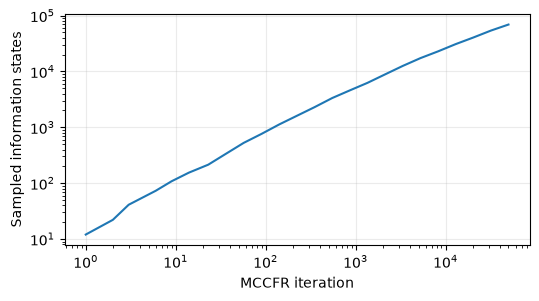

In [3]:
import matplotlib.pyplot as plt

tables, diagnostics = train_mccfr(game)

print(f"training time: {diagnostics['elapsed_seconds']:.1f} seconds")
print("visited information states:", {player: len(table) for player, table in tables.items()})

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(diagnostics["iterations"], diagnostics["information_states"])
ax.set(xscale="log", yscale="log", xlabel="MCCFR iteration", ylabel="Sampled information states")
ax.grid(alpha=0.25)
plt.show()

## Build a batched policy profile

Exact Phantom Tic-Tac-Toe evaluation queries policies in batches. The adapter returns each learned average strategy and uses a uniform distribution over legal actions for information states that the sampled trainer did not visit.

In [4]:
def make_batched_policy_profile(tables):
    average_strategies = {}
    for player, table in tables.items():
        average_strategies[player] = {}
        for key, (_, strategy_sum) in table.items():
            total = strategy_sum.sum()
            if total > 0.0:
                average_strategies[player][key] = strategy_sum / total

    def policy_profile(player, observations, action_space, legal_action_mask):
        del action_space
        packed_observations = np.packbits(np.asarray(observations, dtype=np.bool_), axis=1)
        probabilities = np.empty(legal_action_mask.shape, dtype=float)
        for row, packed_observation in enumerate(packed_observations):
            learned = average_strategies[player].get(packed_observation.tobytes())
            if learned is None:
                mask = legal_action_mask[row]
                probabilities[row] = mask / mask.sum()
            else:
                probabilities[row] = learned
        return probabilities

    return policy_profile


def uniform_policy_profile(player, observations, action_space, legal_action_mask):
    del player, observations, action_space
    return legal_action_mask / legal_action_mask.sum(axis=1, keepdims=True)


policy_profile = make_batched_policy_profile(tables)
initial_time_step = game.new_env().reset(seed=0)
initial_mask = np.ones((1, len(game.action_spaces[0])), dtype=bool)
initial_strategy = policy_profile(
    0, np.asarray((initial_time_step.observations[0],)), game.action_spaces[0], initial_mask
)[0]
print("player 0's learned opening strategy:")
print(initial_strategy.round(3).reshape(3, 3))

player 0's learned opening strategy:
[[0.012 0.077 0.044]
 [0.018 0.412 0.094]
 [0.196 0.063 0.084]]


## Evaluate the trained policy profile

The first exact evaluation constructs and retains the full classical Phantom Tic-Tac-Toe traverser. On the machine used to create this notebook, the two evaluations below take roughly one to two minutes in total and peak near 5.8 GB of resident memory. The second call reuses the traverser.

uniform evaluation: 64.3 seconds
trained evaluation: 45.1 seconds
trained metrics: {'expected_returns': {0: 0.48501857926025826, 1: -0.48501857926025826}, 'player_improvements': {0: 0.5006866475658291, 1: 0.6733527013729909}, 'nash_conv': 1.1740393489388201, 'exploitability': 0.5870196744694101}


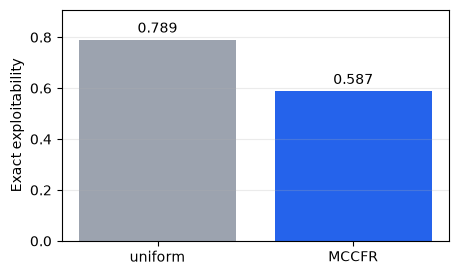

{'uniform': {'expected_returns': {0: 0.2968253968176363,
   1: -0.2968253968176363},
  'player_improvements': {0: 0.6562996031853496, 1: 0.9211640211532768},
  'nash_conv': 1.5774636243386264,
  'exploitability': 0.7887318121693132},
 'trained': {'expected_returns': {0: 0.48501857926025826,
   1: -0.48501857926025826},
  'player_improvements': {0: 0.5006866475658291, 1: 0.6733527013729909},
  'nash_conv': 1.1740393489388201,
  'exploitability': 0.5870196744694101}}

In [5]:
started = perf_counter()
uniform_metrics = game.evaluate(uniform_policy_profile)
uniform_elapsed = perf_counter() - started

started = perf_counter()
trained_metrics = game.evaluate(policy_profile)
trained_elapsed = perf_counter() - started

print(f"uniform evaluation: {uniform_elapsed:.1f} seconds")
print(f"trained evaluation: {trained_elapsed:.1f} seconds")
print("trained metrics:", trained_metrics)

labels = ("uniform", "MCCFR")
exploitabilities = (uniform_metrics["exploitability"], trained_metrics["exploitability"])
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(labels, exploitabilities, color=("#9ca3af", "#2563eb"))
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set(ylabel="Exact exploitability", ylim=(0.0, max(exploitabilities) * 1.15))
ax.grid(axis="y", alpha=0.25)
plt.show()

{"uniform": uniform_metrics, "trained": trained_metrics}

## Reading the result

`expected_returns` gives the value of the fixed policy profile, while each `player_improvements` entry measures how much that player can gain by switching to an exact best response. Their sum is `nash_conv`; BenchMAX reports `exploitability` as half that sum. Lower exploitability is better. With the fixed seed and iteration count above, sampled MCCFR improves substantially over the uniform policy, while leaving ample room for longer training.